Tugas Machine Learning 2

2.1 Persiapan Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

2.2 Import Dataset

In [ ]:
import numpy as np
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    weights=[0.8, 0.2],
    random_state=42
)

print("Distribusi kelas:", np.bincount(y))

Distribusi kelas: [797 203]


2.3 Preprocessing: Stratified Split

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Proporsi kelas train:", np.bincount(y_train) / len(y_train))
print("Proporsi kelas test :", np.bincount(y_test) / len(y_test))

Proporsi kelas train: [0.7975 0.2025]
Proporsi kelas test : [0.795 0.205]


2.4 Training Model & Learning Curve

In [ ]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="accuracy"
)
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

2.5 Evaluasi

In [ ]:
print("Skor train pada ukuran data terbesar :", round(train_mean[-1], 3))
print("Skor validasi pada ukuran data terbesar:", round(val_mean[-1], 3))
print("Gap (indikasi overfitting jika besar)  :", round(train_mean[-1] - val_mean[-1], 3))

Skor train pada ukuran data terbesar : 0.929
Skor validasi pada ukuran data terbesar: 0.885
Gap (indikasi overfitting jika besar)  : 0.044


2.6 Visualisasi

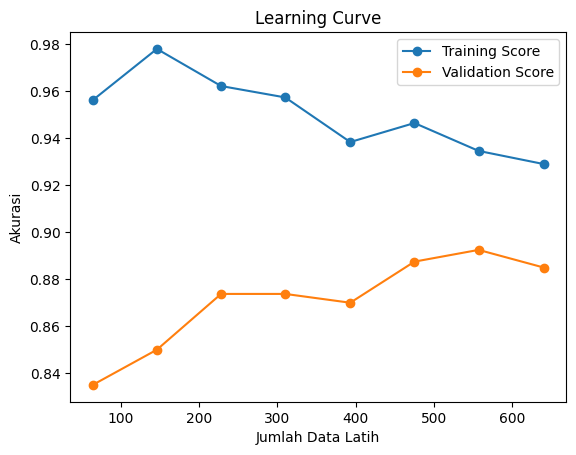

In [ ]:
plt.plot(train_sizes, train_mean, 'o-', label='Training Score')
plt.plot(train_sizes, val_mean, 'o-', label='Validation Score')
plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve')
plt.legend()
plt.show()

2.7 Praktikum 1

In [ ]:
print("1. Business Understanding")
print("Memprediksi pelanggan yang akan berhenti berlangganan")
print("untuk membantu perusahaan mempertahankan pelanggan.")

print("\n2. Data Understanding")
print("Mengumpulkan dan memahami data pelanggan,")
print("seperti lama berlangganan, biaya bulanan,")
print("jenis layanan, dan status churn.")

print("\n3. Data Preparation")
print("Membersihkan data kosong dan duplikat,")
print("mengubah data kategorikal menjadi numerik,")
print("serta memilih fitur yang relevan.")

print("\n4. Modeling")
print("Membangun model prediksi menggunakan")
print("algoritma Logistic Regression.")

print("\n5. Evaluation")
print("Mengevaluasi model menggunakan Accuracy,")
print("Precision, Recall, dan F1-Score.")

print("\n6. Deployment")
print("Menerapkan model untuk membantu perusahaan")
print("mengidentifikasi pelanggan yang berisiko churn.")

1. Business Understanding
Memprediksi pelanggan yang akan berhenti berlangganan
untuk membantu perusahaan mempertahankan pelanggan.

2. Data Understanding
Mengumpulkan dan memahami data pelanggan,
seperti lama berlangganan, biaya bulanan,
jenis layanan, dan status churn.

3. Data Preparation
Membersihkan data kosong dan duplikat,
mengubah data kategorikal menjadi numerik,
serta memilih fitur yang relevan.

4. Modeling
Membangun model prediksi menggunakan
algoritma Logistic Regression.

5. Evaluation
Mengevaluasi model menggunakan Accuracy,
Precision, Recall, dan F1-Score.

6. Deployment
Menerapkan model untuk membantu perusahaan
mengidentifikasi pelanggan yang berisiko churn.


2.7 Praktikum 2

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, learning_curve
import numpy as np


data = load_breast_cancer()
X = data.data
y = data.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


for depth in [1, 4, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    train_sizes, train_scores, val_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 6),
        scoring="accuracy"
    )

    train_mean = train_scores.mean()
    val_mean = val_scores.mean()

    print(f"\nmax_depth={depth}")
    print(f"Train Score: {train_mean:.3f}")
    print(f"Validation Score: {val_mean:.3f}")

    if train_mean < 0.80 and val_mean < 0.80:
        print("Diagnosis: Underfitting")
    elif train_mean - val_mean > 0.10:
        print("Diagnosis: Overfitting")
    else:
        print("Diagnosis: Seimbang")


max_depth=1
Train Score: 0.940
Validation Score: 0.902
Diagnosis: Seimbang

max_depth=4
Train Score: 0.994
Validation Score: 0.920
Diagnosis: Seimbang

max_depth=None
Train Score: 1.000
Validation Score: 0.910
Diagnosis: Seimbang


2.7 Praktikum

max_depth=1: train=0.849, val=0.800
max_depth=4: train=0.952, val=0.866
max_depth=None: train=1.000, val=0.858


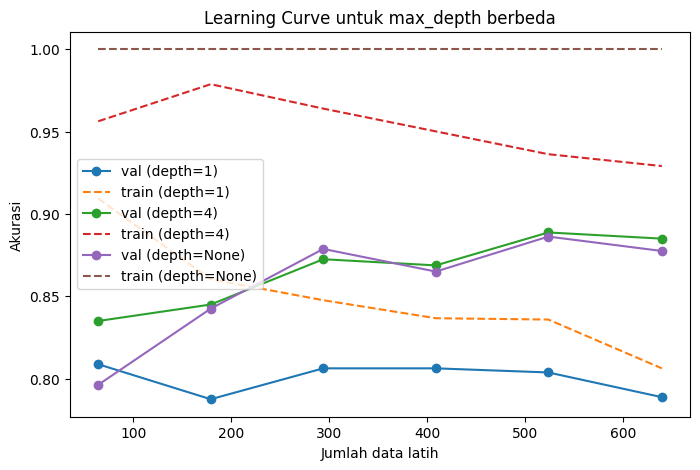

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier


X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    weights=[0.8, 0.2],
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

plt.figure(figsize=(8, 5))

for depth in [1, 4, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)

    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 6)
    )

    print(
        f"max_depth={depth}: "
        f"train={train_scores.mean():.3f}, "
        f"val={val_scores.mean():.3f}"
    )

    plt.plot(train_sizes, val_scores.mean(axis=1), marker='o',
             label=f'val (depth={depth})')
    plt.plot(train_sizes, train_scores.mean(axis=1), linestyle='--',
             label=f'train (depth={depth})')

plt.xlabel('Jumlah data latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve untuk max_depth berbeda')
plt.legend()
plt.show()